# Bias–Variance Trade-off in Polynomial Regression

Fit polynomial degrees 1–20 to the same noisy nonlinear function and compare training vs. test error. Underfitting at low degree (test MSE 114 at degree 1), the best generalization at **degree 8 (test MSE 2.50)**, and overfitting as degree keeps rising.

# 4
### (a)

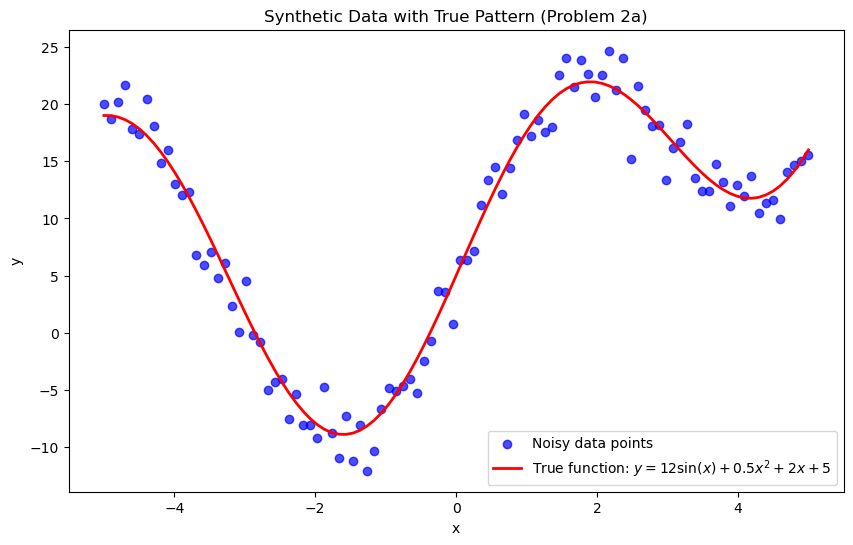

In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

np.random.seed(42)
x = np.linspace(-5, 5, 100)
y_true = 12*np.sin(x)+0.5*x**2+2*x+5
y_noisy = y_true+np.random.normal(0,2,size=len(x))
plt.figure(figsize=(10, 6))

plt.scatter(x, y_noisy, alpha=0.7, label='Noisy data points', color='blue')
plt.plot(x, y_true, 'r-', linewidth=2, label='True function: $y = 12\\sin(x) + 0.5x^2 + 2x + 5$')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Synthetic Data with True Pattern (Problem 2a)')
plt.legend()
plt.show()

### (b)

In [9]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

pipeline = Pipeline([('poly_features', PolynomialFeatures()),('linear_regression', LinearRegression())])

### (c)

In [10]:
from sklearn.model_selection import train_test_split

X = np.array(x).reshape(-1, 1)  
y = y_noisy  

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### (d)

testing error of degree 2:81.28127990187967
testing error of degree 4:28.255465356027305
testing error of degree 6:3.8345175609549096
testing error of degree 8:2.497375253198391
testing error of degree 10:3.288430962322738
testing error of degree 12:4.873136637588435


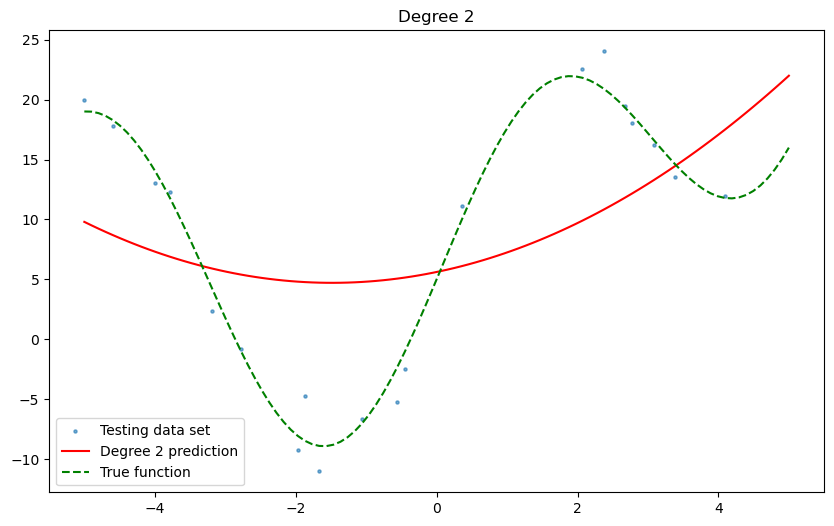

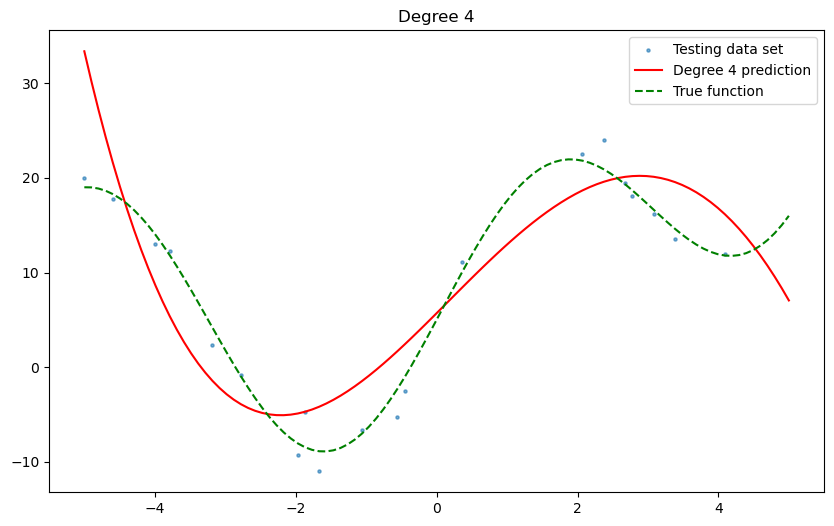

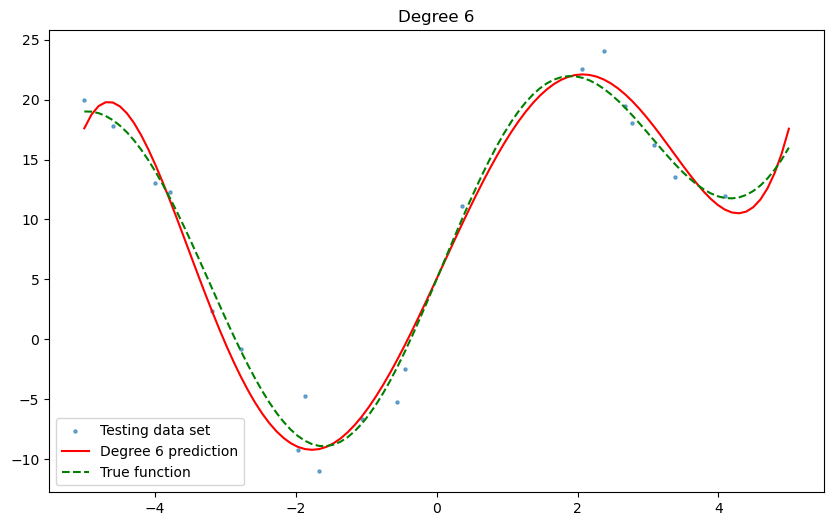

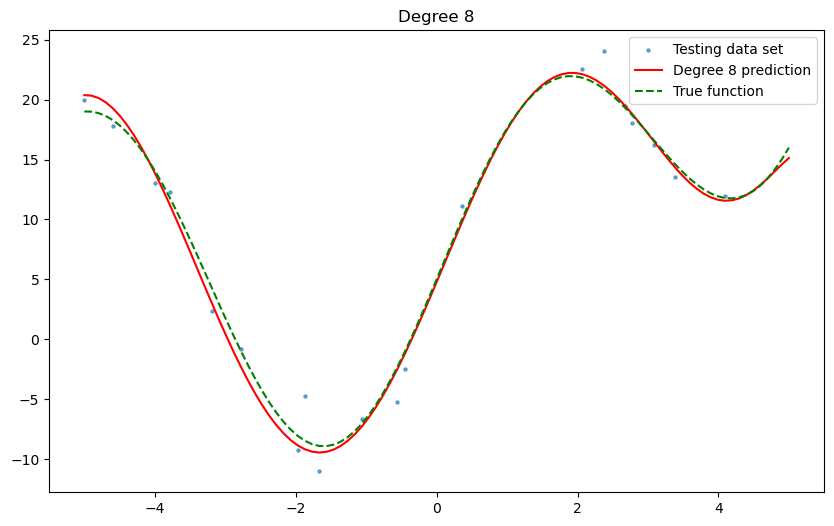

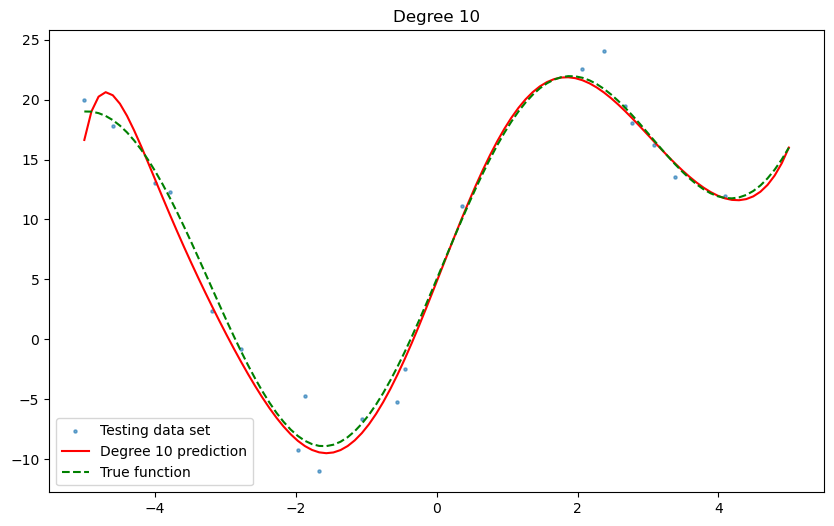

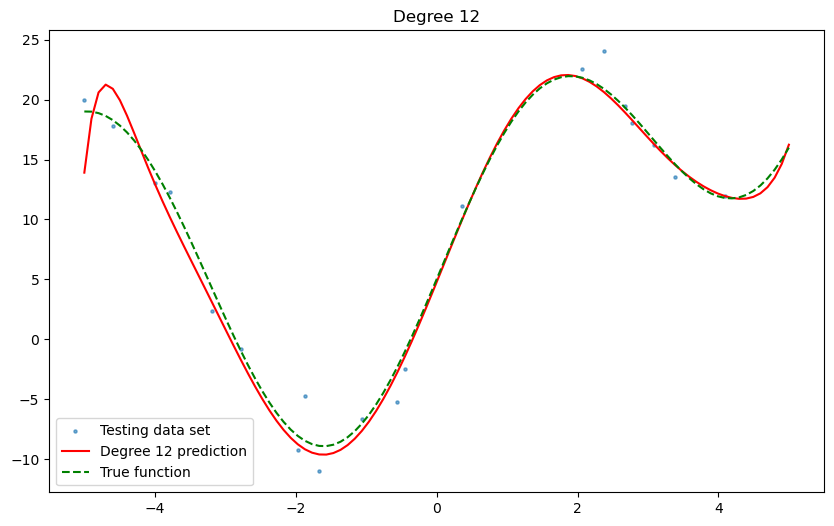

In [11]:
from sklearn.metrics import mean_squared_error

degrees_d = [2,4,6,8,10,12]

for i,degree in enumerate(degrees_d):
    pipeline.set_params(poly_features__degree=degree)
    pipeline.fit(X_train, y_train)
    
    y_test_pred = pipeline.predict(X_test)
    test_error = mean_squared_error(y_test, y_test_pred)
    print(f"testing error of degree {degree}:{test_error}")
    
    x_plot = np.linspace(-5, 5, 100)
    y_plot = pipeline.predict(x_plot.reshape(-1, 1))
    
    plt.figure(figsize=(10, 6))
    plt.scatter(X_test, y_test, alpha=0.6, label='Testing data set',s=5)
    plt.plot(x_plot, y_plot, 'r-', label=f'Degree {degree} prediction')
    plt.plot(x, y_true, 'g--', label='True function')
    plt.title(f'Degree {degree}')
    plt.legend()
  
plt.show()

### (e)

testing error of degree 1:114.04574172678565
testing error of degree 2:81.28127990187967
testing error of degree 5:3.66746983817396
testing error of degree 8:2.497375253198391
testing error of degree 12:4.873136637588435
testing error of degree 14:3.9590161411450184
testing error of degree 16:3.4069829204344044
testing error of degree 18:11.146325158622203
testing error of degree 20:82.72125262655824


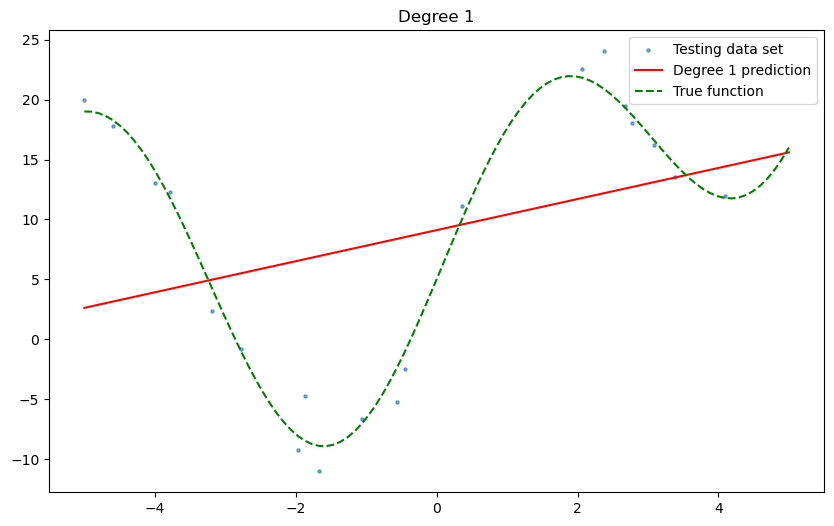

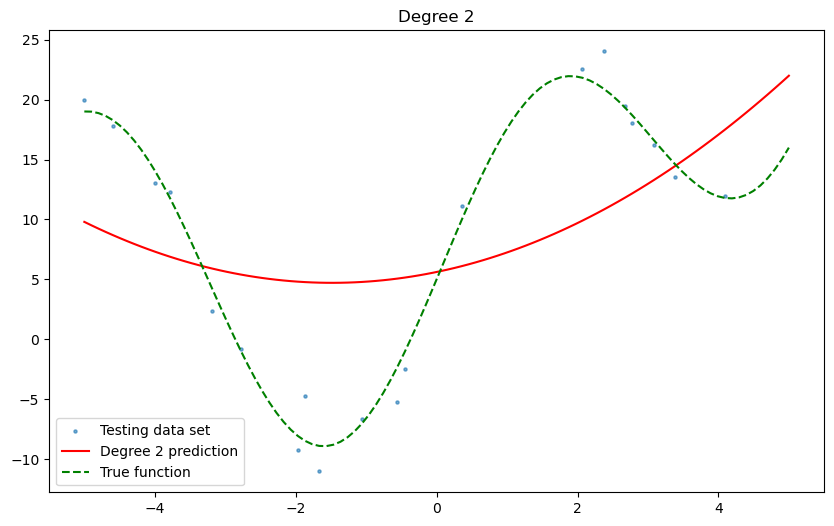

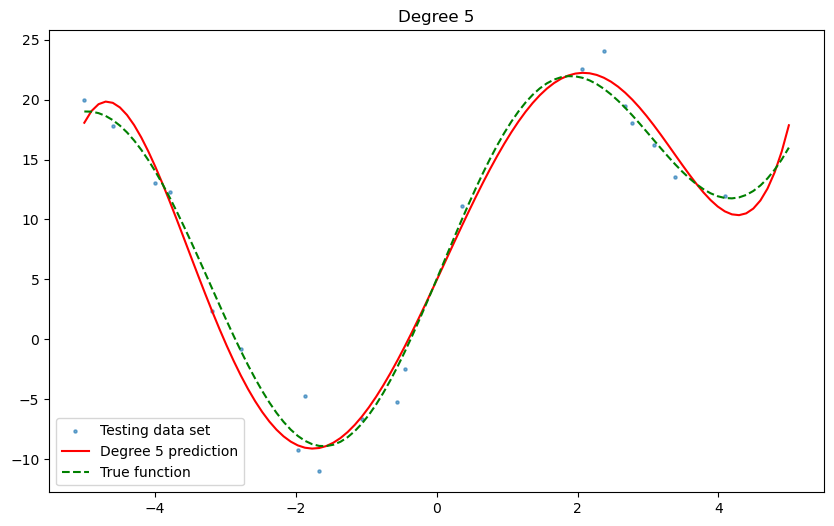

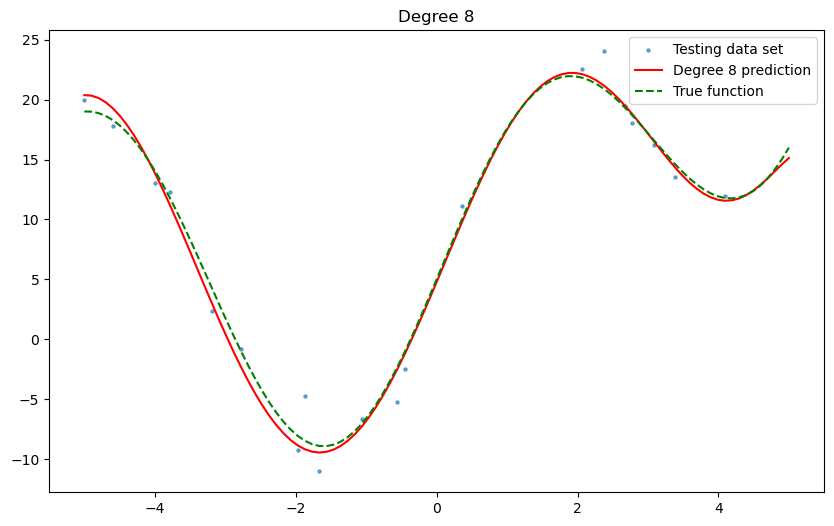

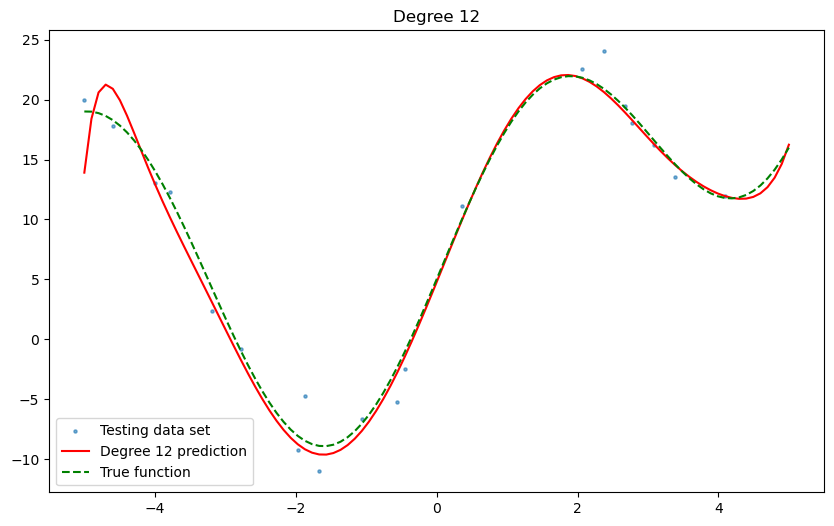

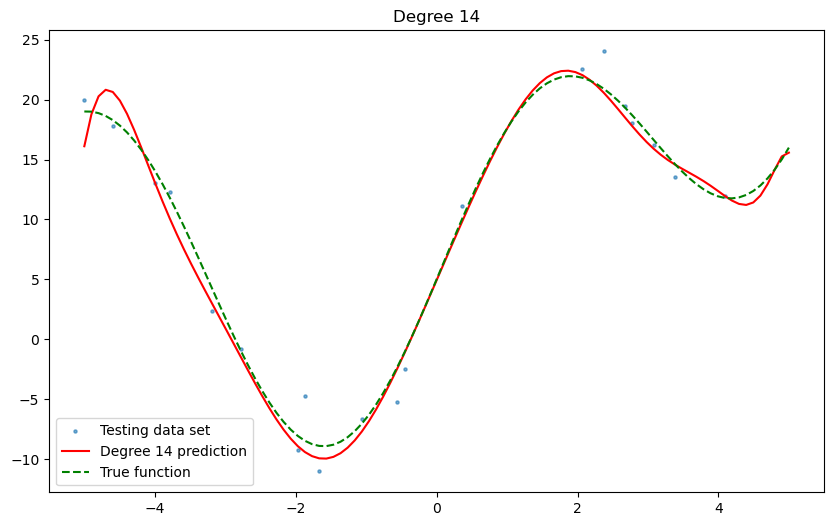

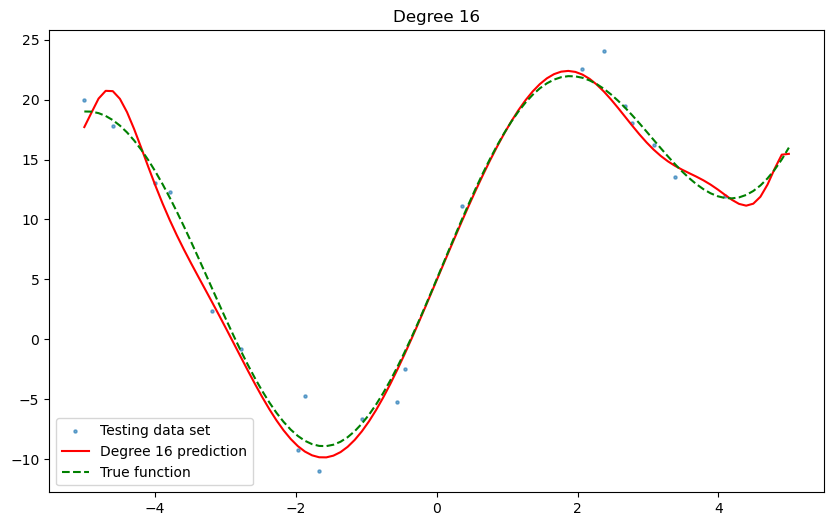

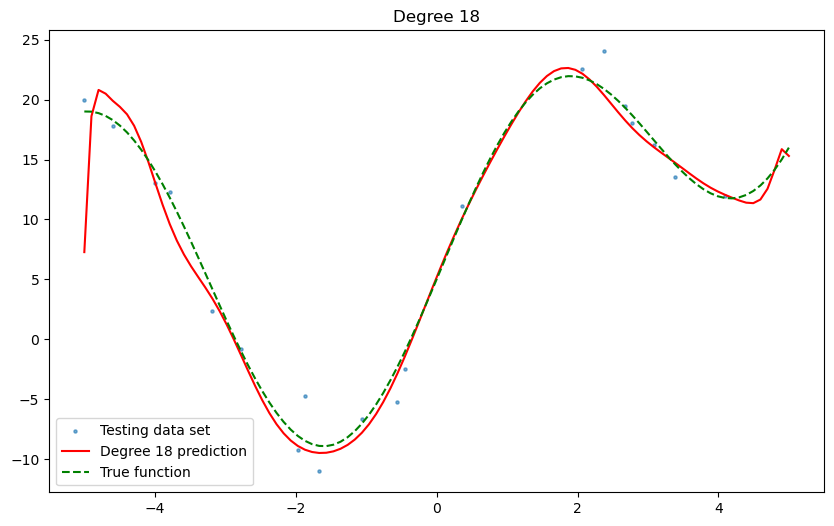

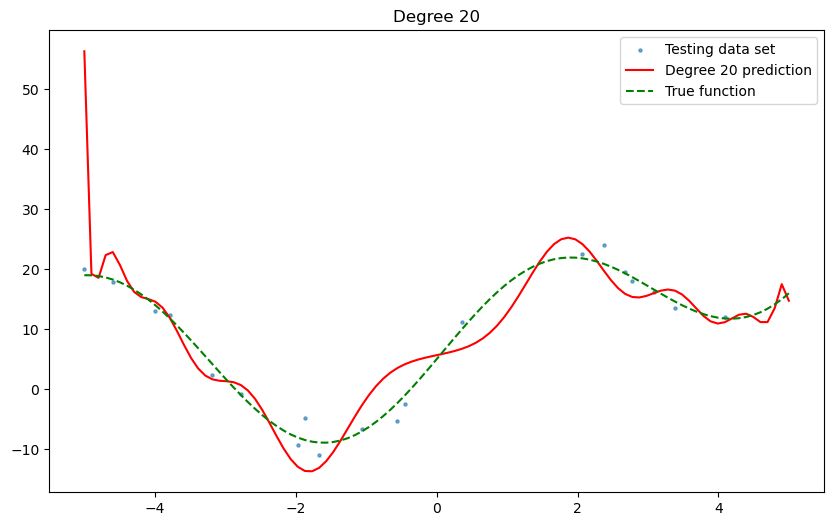

In [12]:
degrees_e = [1, 2, 5, 8, 12, 14, 16, 18, 20]

for i,degree in enumerate(degrees_e):
    pipeline.set_params(poly_features__degree=degree)
    pipeline.fit(X_train, y_train)
    
    y_test_pred = pipeline.predict(X_test)
    test_error = mean_squared_error(y_test, y_test_pred)
    print(f"testing error of degree {degree}:{test_error}")
     
    x_plot = np.linspace(-5, 5, 100)
    y_plot = pipeline.predict(x_plot.reshape(-1, 1))
    
    plt.figure(figsize=(10, 6))
    plt.scatter(X_test, y_test, alpha=0.6, label='Testing data set',s=5)
    plt.plot(x_plot, y_plot, 'r-', label=f'Degree {degree} prediction')
    plt.plot(x, y_true, 'g--', label='True function')
    plt.title(f'Degree {degree}')
    plt.legend()
  
plt.show()

### (f)

testing error of degree 1:114.04574172678565
testing error of degree 2:81.28127990187967
testing error of degree 5:3.66746983817396
testing error of degree 8:2.497375253198391
testing error of degree 12:4.873136637588435
testing error of degree 14:3.9590161411450184
testing error of degree 16:3.4069829204344044
testing error of degree 18:11.146325158622203
testing error of degree 20:82.72125262655824


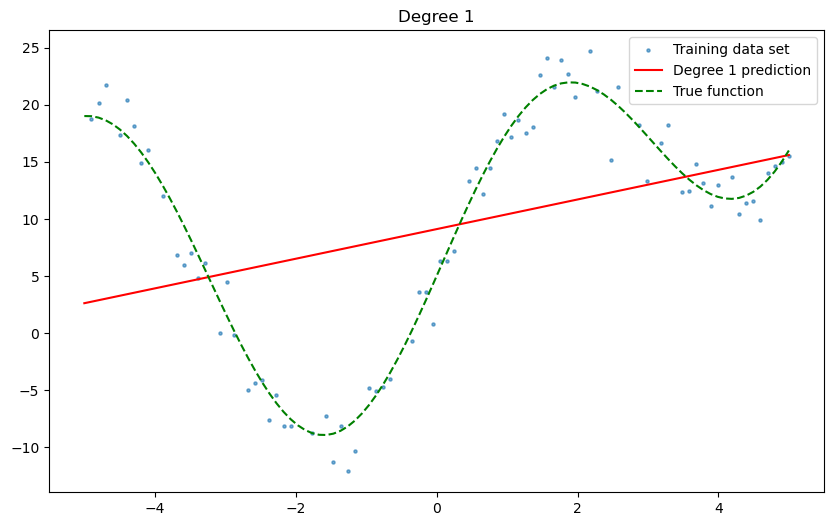

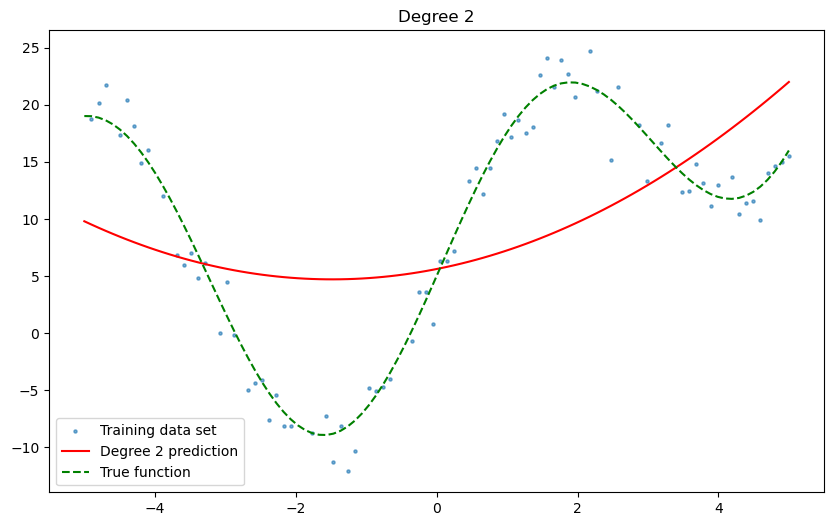

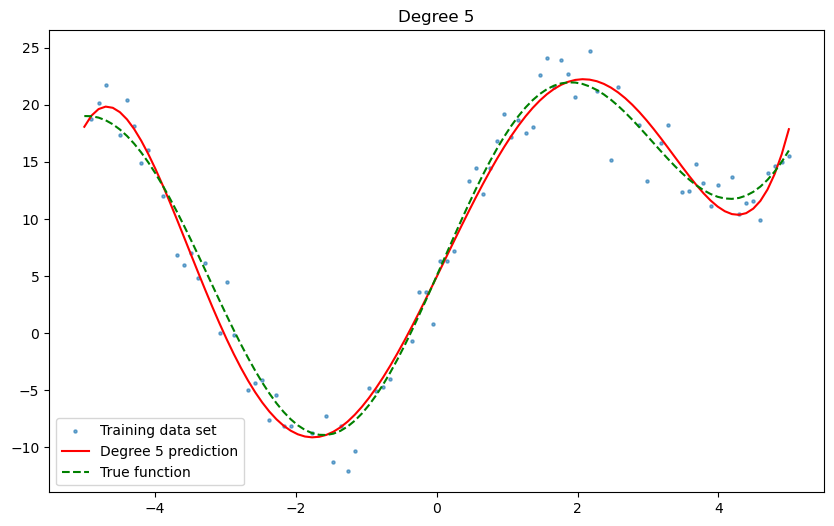

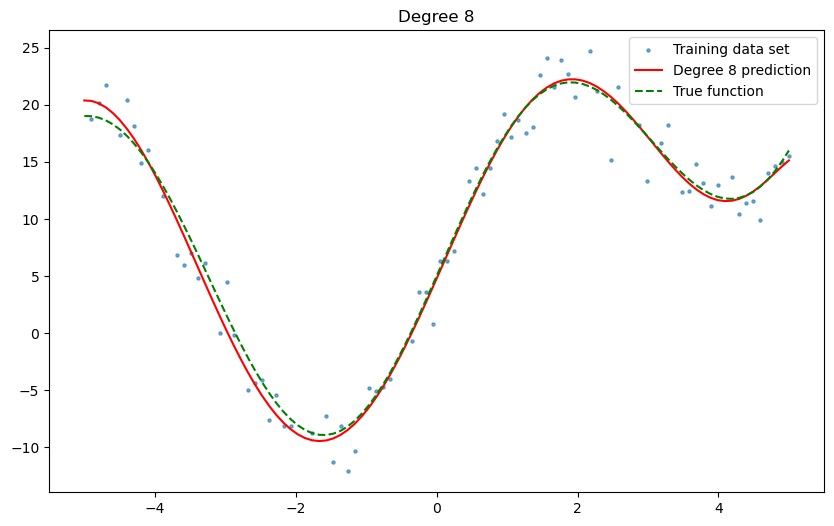

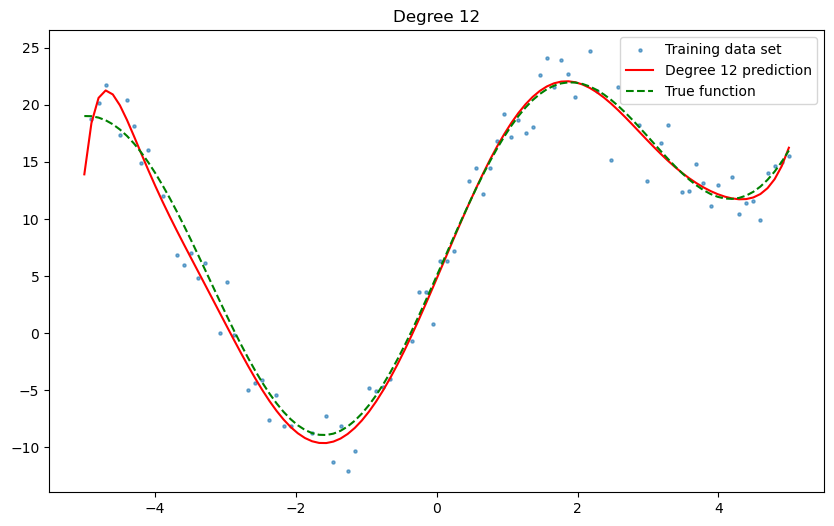

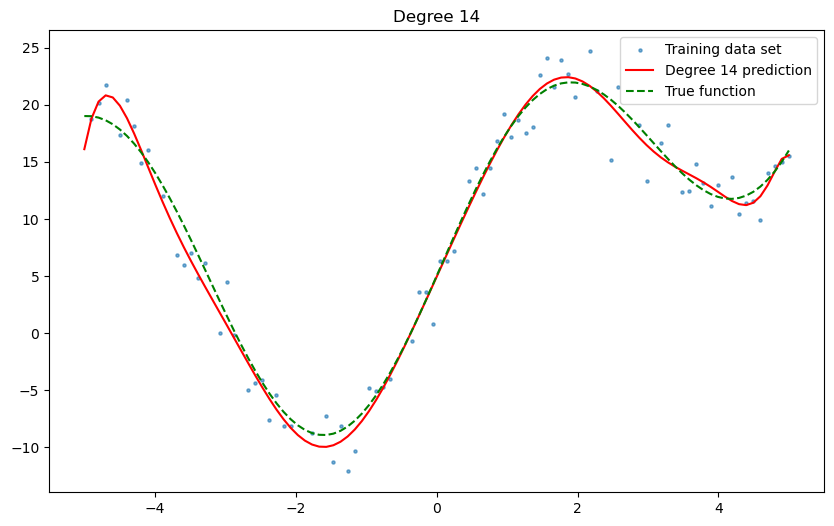

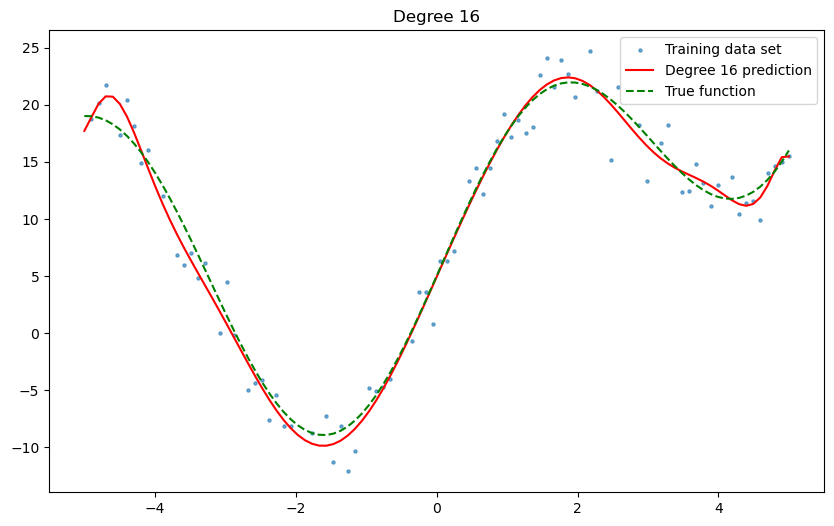

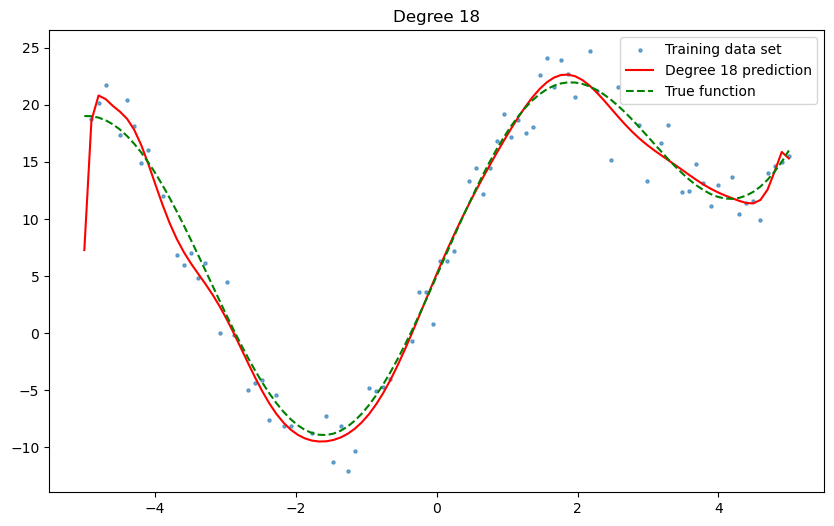

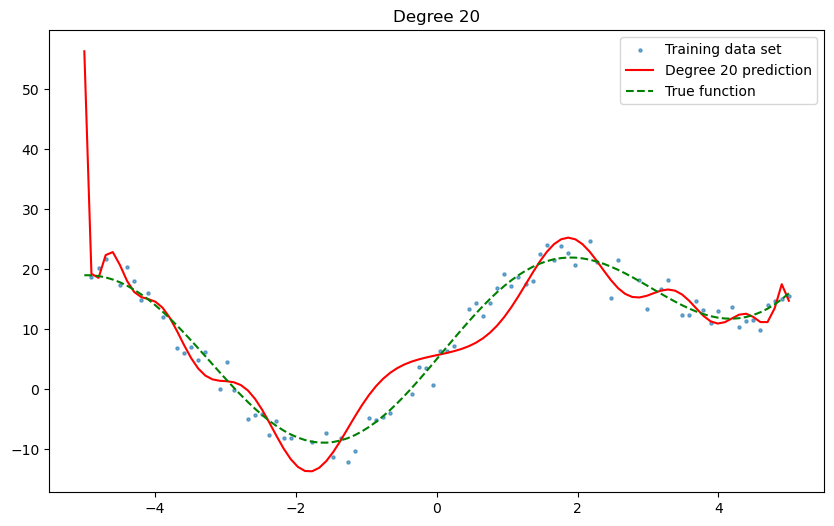

In [13]:
for i,degree in enumerate(degrees_e):
    pipeline.set_params(poly_features__degree=degree)
    pipeline.fit(X_train, y_train)
    
    y_test_pred = pipeline.predict(X_test)
    test_error = mean_squared_error(y_test, y_test_pred)
    print(f"testing error of degree {degree}:{test_error}")
     
    x_plot = np.linspace(-5, 5, 100)
    y_plot = pipeline.predict(x_plot.reshape(-1, 1))
    
    plt.figure(figsize=(10, 6))
    plt.scatter(X_train, y_train, alpha=0.6, label='Training data set',s=5)
    plt.plot(x_plot, y_plot, 'r-', label=f'Degree {degree} prediction')
    plt.plot(x, y_true, 'g--', label='True function')
    plt.title(f'Degree {degree}')
    plt.legend()
  
plt.show()

#### Degree 20 fit the best to the training data. But it is not the best degree. The optimal degree not only needs to ensure good fit of the model on training data, but also needs to enable the model to have good generalization performance. This means there is a good fit on the testing data, but according to the graph made in the previous question, when the degree is equal to 20, it does not fit well with the testing data. According to the results of G's question, 8 degrees is indeed the best.

### (g)

training error of degree 1:114.04574172678565
testing error of degree 1:114.04574172678565
training error of degree 2:81.28127990187967
testing error of degree 2:81.28127990187967
training error of degree 3:24.63412926451027
testing error of degree 3:24.63412926451027
training error of degree 4:28.255465356027305
testing error of degree 4:28.255465356027305
training error of degree 5:3.66746983817396
testing error of degree 5:3.66746983817396
training error of degree 6:3.8345175609549096
testing error of degree 6:3.8345175609549096
training error of degree 7:2.6486266759609394
testing error of degree 7:2.6486266759609394
training error of degree 8:2.497375253198391
testing error of degree 8:2.497375253198391
training error of degree 9:2.9766767387420905
testing error of degree 9:2.9766767387420905
training error of degree 10:3.288430962322738
testing error of degree 10:3.288430962322738
training error of degree 11:4.232938823486757
testing error of degree 11:4.232938823486757
training 

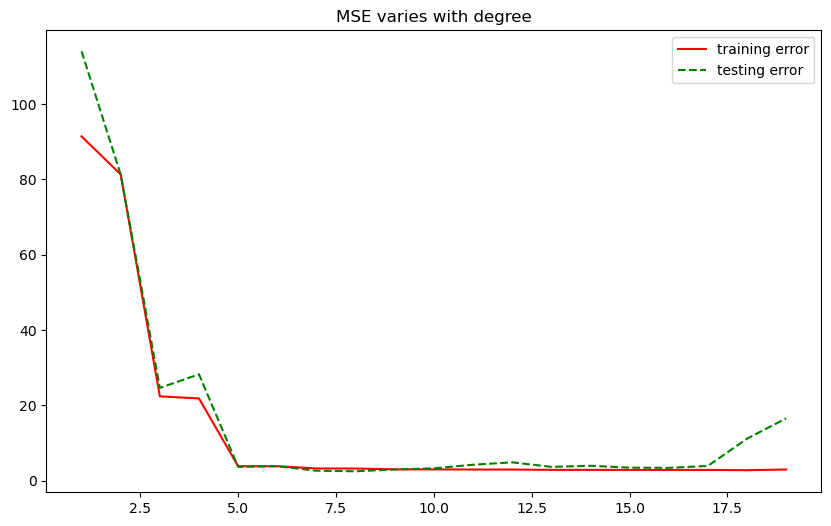

In [14]:
degrees_g = np.array(list(range(1, 20)))
train_errors = []
test_errors = []

for i,degree in enumerate(degrees_g):
    pipeline.set_params(poly_features__degree=degree)
    pipeline.fit(X_train, y_train)
    
    y_train_pred = pipeline.predict(X_train)
    y_test_pred = pipeline.predict(X_test)
    train_error = mean_squared_error(y_train, y_train_pred)
    test_error = mean_squared_error(y_test, y_test_pred)
    train_errors.append(train_error)
    test_errors.append(test_error)
    print(f"training error of degree {degree}:{test_error}")
    print(f"testing error of degree {degree}:{test_error}")
    
plt.figure(figsize=(10, 6))
plt.plot(degrees_g, train_errors, 'r-', label='training error')
plt.plot(degrees_g, test_errors, 'g--', label='testing error')
plt.title(f'MSE varies with degree')
plt.legend()
  
plt.show()

> Note: in the printed output above, the "training error" lines repeat the test error because of a print typo (`test_error` instead of `train_error`). The plot uses the correct training-error values.

### Yes, this confirms my conclusion in question "f". 
### Underfitting means a large training MSE and a large testing MSE. This means that the model fits poorly and does not fit well with the original data. 
### Overfitting means although the training MSE is small, the testing MSE is large. This means that the model only fits well on the training data set, and does not fit well with other data, indicating that the generalization performance of this model is not good.
### From this search that traverses 1-19 degrees, it can be seen that the model has the best generalization performance when the degree is 8.